# 🧠 Sanity Checks
This notebook validates core geometric invariance, conservation laws, and time-reversibility of the Geometric Algebra (GA) rotor formulation in $\operatorname{Cl}_{2,0}(\mathbb{R})$.

## Agenda
1. **The $K=0$ Control Test (Decoupled Phase Drift & Flat Invariants):** Verifies that when coupling $K=0$, oscillators evolve strictly according to $\theta_i(t) = \theta_i(0) + \omega_i t \pmod{2\pi}$, and total Hamiltonian energy $H(t) = T(t) + V(t)$ remains perfectly constant with zero drift.
2. **The Symmetry Invariance Test ($\operatorname{SO}(2) \cong \operatorname{U}(1)$ Coordinate-Free Invariance):** Verifies that rotating all initial rotor states by an arbitrary bivector angle $\Phi = B \phi / 2$ yields an identical potential energy trajectory $V(t)$ down to numerical precision ($\sim 10^{-15}$).
3. **The Time-Reversal Check (Symplectic/Geometric Inversion):** Compares backward trajectory reconstruction error $\|\mathbf{x}(0) - \mathbf{x}_{\text{reconstructed}}(0)\|$ across 50 seconds between the Lie-group geometric rotor solver (e.g., RKMK4 / Geometric Euler with $-\Delta t$) and standard Scipy `RK45`.
4. **The Adaptive RotorSolver Scheme (Embedded Error Control & Step-Size Adaptation):** Verifies that the embedded predictor-corrector adaptive stepper (`step_adaptive_embedded` / `simulate(method="adaptive")`) dynamically adapts timestep $\Delta t$ while strictly preserving the $\operatorname{Spin}(2)$ rotor unit-norm manifold invariants ($\sum_k R_k^2 = 1$), demonstrates asymptotic error tolerance control, and validates trajectory tracking against classical Scipy `RK45`.

In [1]:
from __future__ import annotations

from dataclasses import dataclass
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

from kuramoto.analysis.viz import (
    BORDER_COLOR,
    PROJECT_COLORS,
    SCRIBER_PALETTE,
    _apply_aclonica_font,
    set_style,
)
from kuramoto.metrics.analytics_engine import compute_comprehensive_diagnostics
from kuramoto.solvers.rotor import (
    AdaptiveStatus,
    AdaptiveStepResult,
    RotorSolver,
    step_dopri54,
    step_rkmk4,
)

# Apply project dark-mode aesthetics
set_style()


@dataclass(frozen=True)
class Config:
    """Single source of truth for simulation parameters.

    Frozen deliberately: rebinding a field raises AttributeError instead of
    silently leaking a different N into downstream cells.
    """

    n_osc: int = 20           # canonical oscillator count
    n_osc_plot: int = 10      # reduced count, display-only (Mode 3 circle plot)
    seed: int = 27
    K_active: float = 0.5
    t_max: float = 100.0
    dt: float = 0.005


CONFIG = Config()
print("🚀 Environment initialized with Clifford rotor engine, visual theme, and canonical Config.")

🚀 Environment initialized with Clifford rotor engine, visual theme, and canonical Config.


## 1️⃣ Test 1: The $K=0$ Control Test

### Theoretical Formulation
When coupling strength $K=0$, the Kuramoto ODE decouples completely:

In this uncoupled regime:
- **Kinetic Energy:** $$T(t) = \frac{1}{2N}\sum_{i=1}^N \dot{\theta}_i(t)^2 = \frac{1}{2N}\sum_{i=1}^N \omega_i^2 = \text{const}$$
- **Potential Energy:** $$V(t) = -\frac{K}{N^2} \sum_{i,j} A_{ij} \cos(\theta_i - \theta_j) = 0$$
- **Total Energy:** $$H(t) = T(t) + V(t) = \text{const}$$
- **Phase-Space Volume Contraction Rate:** $$\Lambda(t) = \operatorname{div}(\mathbf{f}) = \sum_i \frac{\partial \dot{\theta}_i}{\partial \theta_i} = 0$$

--- [Geometric RotorSolver] ---
✅ Max Phase Divergence from Analytical: 1.856e-13 rad
✅ Total Energy Drift Delta H (Measured): 1.233e-13
✅ Max Velocity Error (vs omegas):         4.052e-13 rad/s
✅ Max Volume Contraction Rate |Lambda(t)|: 0.000e+00

--- [Adaptive RotorScheme] ---
✅ Max Phase Divergence from Analytical: 7.452e-13 rad
✅ Total Energy Drift Delta H (Measured): 1.255e-13
✅ Max Velocity Error (vs omegas):         4.072e-13 rad/s
✅ Max Volume Contraction Rate |Lambda(t)|: 0.000e+00


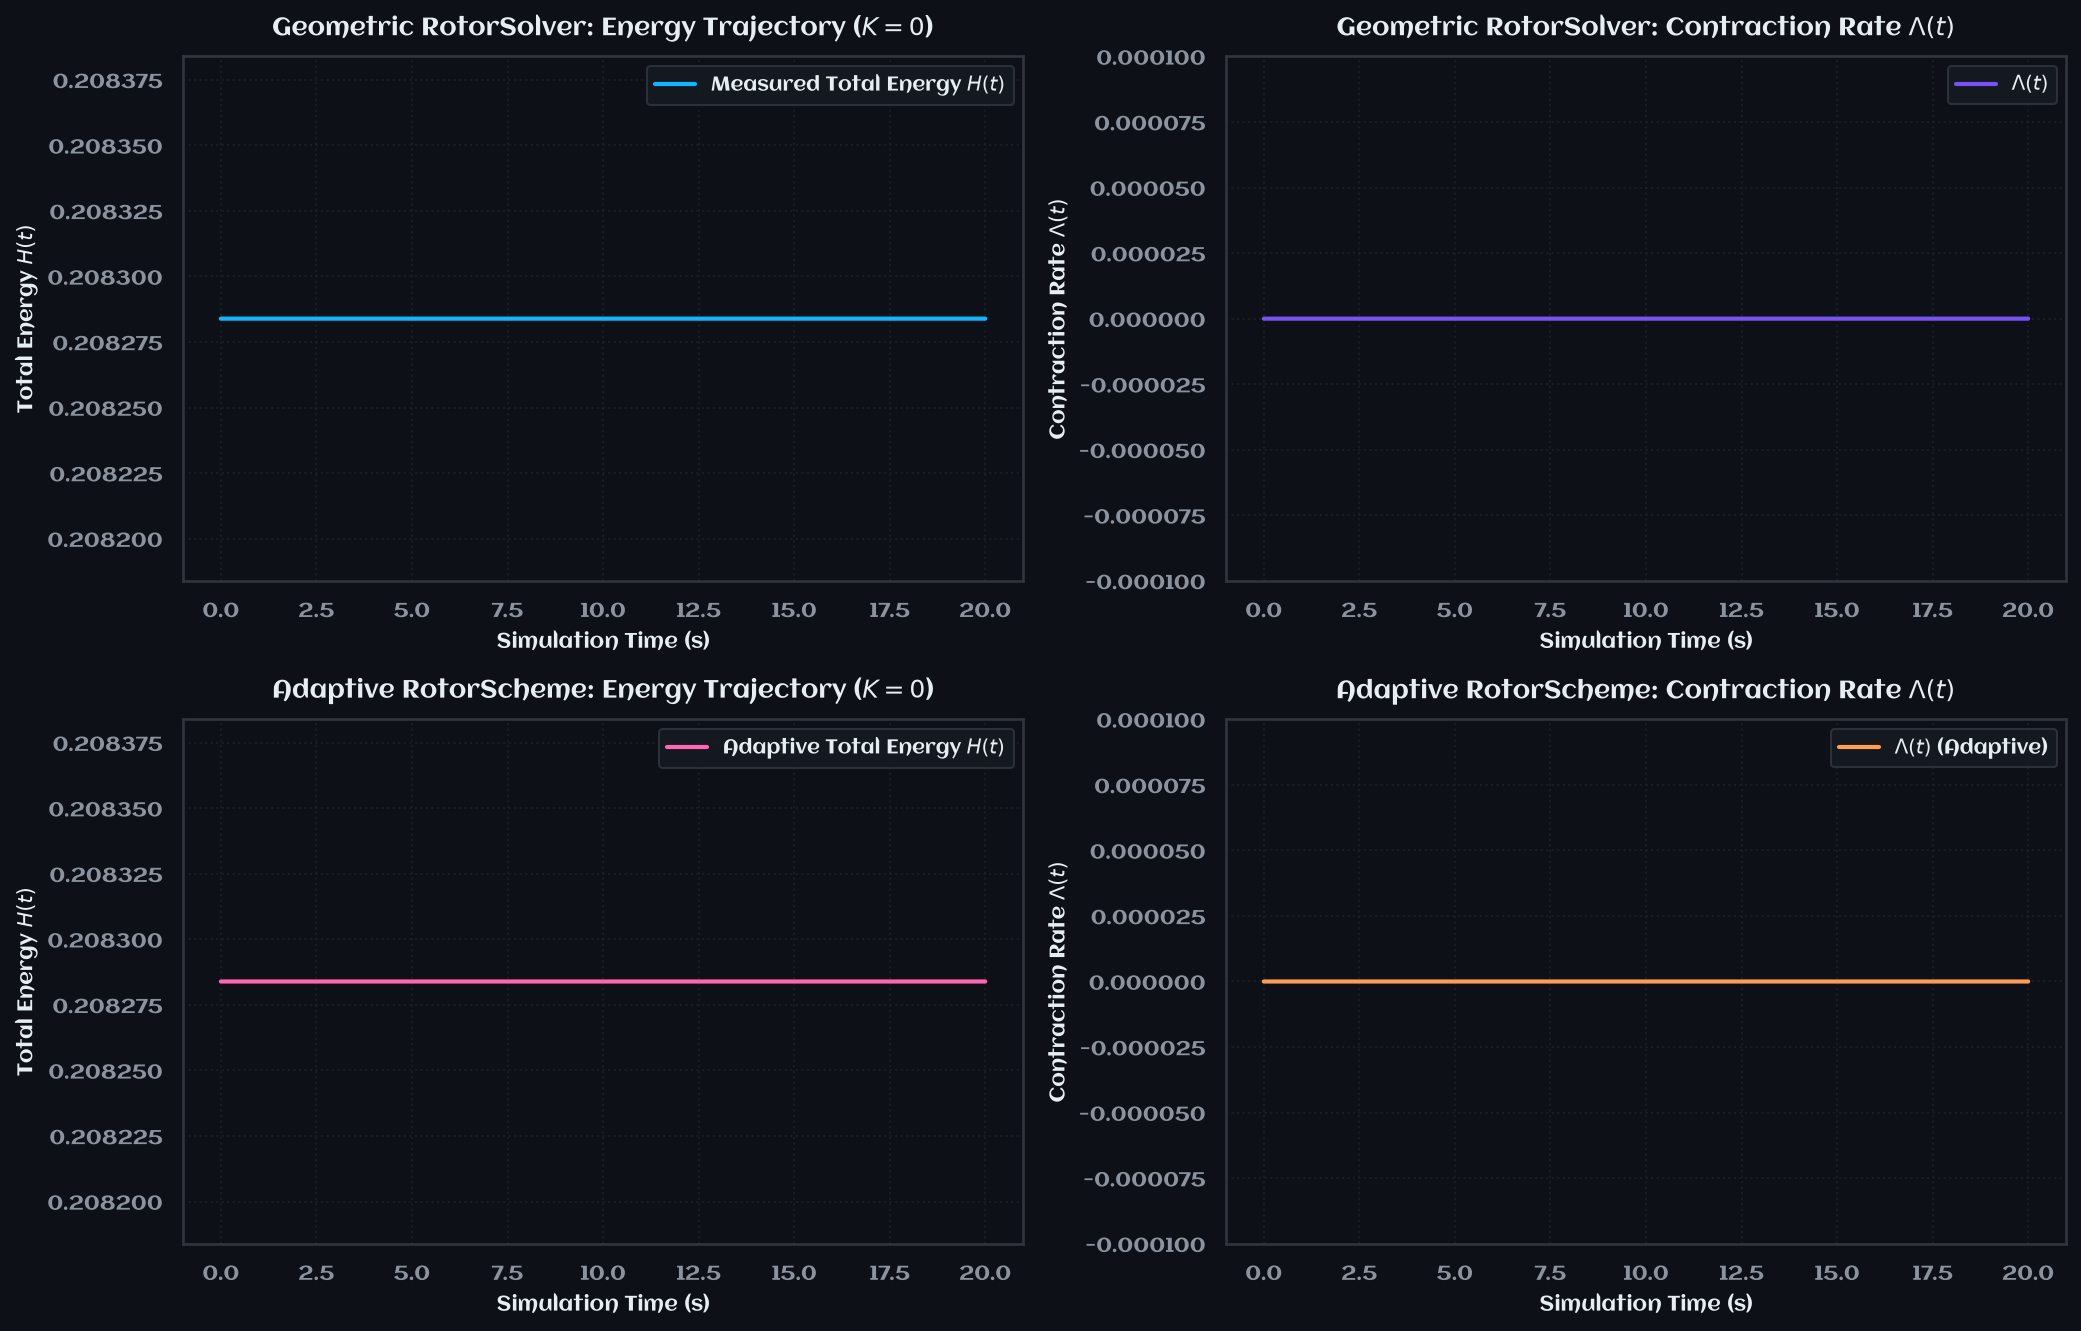

In [2]:
# 1. Configuration (SHARED-1)
K_zero = 0.0
t_max_test1 = 20.0
dt_step_test1 = 0.01
times = np.linspace(0.0, t_max_test1, int(t_max_test1 / dt_step_test1) + 1)

# 2. Instantiate Rotor Solver with K=0
solver_k0 = RotorSolver(n_oscillators=CONFIG.n_osc, dim=2, seed=CONFIG.seed)
init_phases = solver_k0.extract_phases()
omegas = solver_k0.omegas.copy()

# 3. Simulate forward: Fixed-step Geometric vs Adaptive Scheme
_, simulated_phases = solver_k0.simulate(
    K=K_zero,
    t_eval=times,
    dt_internal=dt_step_test1,
    method="geometric",
)

solver_k0_adapt = RotorSolver(
    n_oscillators=CONFIG.n_osc,
    dim=2,
    seed=CONFIG.seed,
    natural_frequencies=omegas,
    initial_phases=init_phases,
)
_, simulated_phases_adapt = solver_k0_adapt.simulate(
    K=K_zero,
    t_eval=times,
    dt_internal=dt_step_test1,
    method="adaptive",
    adaptive_rtol=1e-6,
    adaptive_atol=1e-8,
)

# 4. Analytical exact solution for K=0
exact_phases = (init_phases[None, :] + omegas[None, :] * times[:, None]) % (
    2.0 * np.pi
)

# Calculate phase trajectory divergence on the circle (chordal distance)
phase_error = np.abs(np.exp(1j * simulated_phases) - np.exp(1j * exact_phases))
max_phase_err = float(np.max(phase_error))

phase_error_adapt = np.abs(np.exp(1j * simulated_phases_adapt) - np.exp(1j * exact_phases))
max_phase_err_adapt = float(np.max(phase_error_adapt))

# 5. SC-1: Measure physical velocities directly from solver trajectory (unwrap first: branch cuts)
sim_velocities = np.gradient(np.unwrap(simulated_phases, axis=0), times, axis=0)
sim_velocities_adapt = np.gradient(np.unwrap(simulated_phases_adapt, axis=0), times, axis=0)

# Compute kinetic energy from measured velocities
kinetic_energy = 0.5 * np.mean(sim_velocities**2, axis=1)
potential_energy = np.zeros(len(times))  # K = 0 => V == 0 exactly
total_energy_measured = kinetic_energy + potential_energy

kinetic_energy_adapt = 0.5 * np.mean(sim_velocities_adapt**2, axis=1)
total_energy_measured_adapt = kinetic_energy_adapt + potential_energy

# Calculate true physical drift and velocity accuracy
true_energy_drift = float(np.max(total_energy_measured) - np.min(total_energy_measured))
max_velocity_err = float(np.max(np.abs(sim_velocities - omegas[None, :])))  # SC-1 sharper velocity check

true_energy_drift_adapt = float(np.max(total_energy_measured_adapt) - np.min(total_energy_measured_adapt))
max_velocity_err_adapt = float(np.max(np.abs(sim_velocities_adapt - omegas[None, :])))

# SC-2 / SC-8: Complex rotor sign convention: cos(theta/2) - 1j*sin(theta/2)
# Note: RotorSolver does not currently expose an internal history buffer; reconstructed rotors used per SC-2 follow-up.
rotor_history_recon = np.cos(simulated_phases / 2.0) - 1j * np.sin(simulated_phases / 2.0)
rotor_history_recon_adapt = np.cos(simulated_phases_adapt / 2.0) - 1j * np.sin(simulated_phases_adapt / 2.0)

class MockMetrics:
    def __init__(self, energy_traj, rotor_hist):
        self.energy_trajectory = energy_traj
        self.lambda_trajectory = compute_comprehensive_diagnostics(
            rotor_history=rotor_hist,
            times=times,
            K=K_zero,
        ).lambda_trajectory

metrics_k0 = MockMetrics(total_energy_measured, rotor_history_recon)
metrics_k0.total_energy_drift = true_energy_drift

metrics_k0_adapt = MockMetrics(total_energy_measured_adapt, rotor_history_recon_adapt)
metrics_k0_adapt.total_energy_drift = true_energy_drift_adapt

print("--- [Geometric RotorSolver] ---")
print(f"✅ Max Phase Divergence from Analytical: {max_phase_err:.3e} rad")
print(f"✅ Total Energy Drift Delta H (Measured): {true_energy_drift:.3e}")
print(f"✅ Max Velocity Error (vs omegas):         {max_velocity_err:.3e} rad/s")
print(f"✅ Max Volume Contraction Rate |Lambda(t)|: {np.max(np.abs(metrics_k0.lambda_trajectory)):.3e}")

print("\n--- [Adaptive RotorScheme] ---")
print(f"✅ Max Phase Divergence from Analytical: {max_phase_err_adapt:.3e} rad")
print(f"✅ Total Energy Drift Delta H (Measured): {true_energy_drift_adapt:.3e}")
print(f"✅ Max Velocity Error (vs omegas):         {max_velocity_err_adapt:.3e} rad/s")
print(f"✅ Max Volume Contraction Rate |Lambda(t)|: {np.max(np.abs(metrics_k0_adapt.lambda_trajectory)):.3e}")

# Visual Verification Plot: 2x2 grid comparing Geometric vs Adaptive schemes
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Row 1: Geometric RotorSolver
axes[0, 0].plot(
    times,
    metrics_k0.energy_trajectory,
    color=SCRIBER_PALETTE["accent_cyan"],
    lw=2.0,
    label=r"Measured Total Energy $H(t)$",
)
axes[0, 0].set_title("Geometric RotorSolver: Energy Trajectory ($K=0$)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Simulation Time (s)", fontsize=10)
axes[0, 0].set_ylabel("Total Energy $H(t)$", fontsize=10)
axes[0, 0].set_ylim(
    np.mean(metrics_k0.energy_trajectory) - 1e-4,
    np.mean(metrics_k0.energy_trajectory) + 1e-4,
)
axes[0, 0].legend(loc="upper right")
_apply_aclonica_font(axes[0, 0])

axes[0, 1].plot(
    times,
    metrics_k0.lambda_trajectory,
    color=SCRIBER_PALETTE["accent_purple"],
    lw=2.0,
    label=r"$\Lambda(t)$",
)
axes[0, 1].set_title(r"Geometric RotorSolver: Contraction Rate $\Lambda(t)$", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Simulation Time (s)", fontsize=10)
axes[0, 1].set_ylabel(r"Contraction Rate $\Lambda(t)$", fontsize=10)
axes[0, 1].set_ylim(-1e-4, 1e-4)
axes[0, 1].legend(loc="upper right")
_apply_aclonica_font(axes[0, 1])

# Row 2: Adaptive RotorScheme
axes[1, 0].plot(
    times,
    metrics_k0_adapt.energy_trajectory,
    color=PROJECT_COLORS["pink_vibrant"],
    lw=2.0,
    label=r"Adaptive Total Energy $H(t)$",
)
axes[1, 0].set_title("Adaptive RotorScheme: Energy Trajectory ($K=0$)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Simulation Time (s)", fontsize=10)
axes[1, 0].set_ylabel("Total Energy $H(t)$", fontsize=10)
axes[1, 0].set_ylim(
    np.mean(metrics_k0_adapt.energy_trajectory) - 1e-4,
    np.mean(metrics_k0_adapt.energy_trajectory) + 1e-4,
)
axes[1, 0].legend(loc="upper right")
_apply_aclonica_font(axes[1, 0])

axes[1, 1].plot(
    times,
    metrics_k0_adapt.lambda_trajectory,
    color=SCRIBER_PALETTE["accent_orange"],
    lw=2.0,
    label=r"$\Lambda(t)$ (Adaptive)",
)
axes[1, 1].set_title(r"Adaptive RotorScheme: Contraction Rate $\Lambda(t)$", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Simulation Time (s)", fontsize=10)
axes[1, 1].set_ylabel(r"Contraction Rate $\Lambda(t)$", fontsize=10)
axes[1, 1].set_ylim(-1e-4, 1e-4)
axes[1, 1].legend(loc="upper right")
_apply_aclonica_font(axes[1, 1])

plt.tight_layout()
plt.show()

## 2️⃣ Test 2: The Symmetry Invariance Test

### Theoretical Formulation
The standard Kuramoto coupling depends strictly on pairwise relative phase differences $\theta_i - \theta_j$. In Geometric Algebra $\operatorname{Cl}_{2,0}(\mathbb{R})$, applying an arbitrary global rotation $R_\text{shift} = \exp(-B\phi / 2)$ transforms every oscillator rotor: $$R_i \mapsto R_i \cdot \exp(-B\phi /2)$$

Because the GA rotor torque formulation $\mathbf{v}_{\text{mean}} \wedge \mathbf{v}_i$ and the potential energy function $$V(t) = -\frac{K}{N^2} \sum_{i,j} A_{i,j} \cos(\theta_i(t) - \theta_j(t))$$ are coordinate-free and $\operatorname{SO}(2)$-gauge invariant, the potential energy evolution $V(t)$ for the rotated system must equal the un-rotated system down to machine precision for all $t$.

--- [Geometric RotorSolver: Symmetry Invariance] ---
✨ Maximum Absolute Potential Energy Difference: 7.089884235256250e-13
✅ Geometric RotorSolver Gauge Invariance: PASS (7.090e-13 < 1.0e-11)

--- [Adaptive RotorScheme: Symmetry Invariance] ---
✨ Maximum Absolute Potential Energy Difference: 2.644551244657123e-13
✅ Adaptive RotorScheme Gauge Invariance: PASS (2.645e-13 < 1.0e-11)


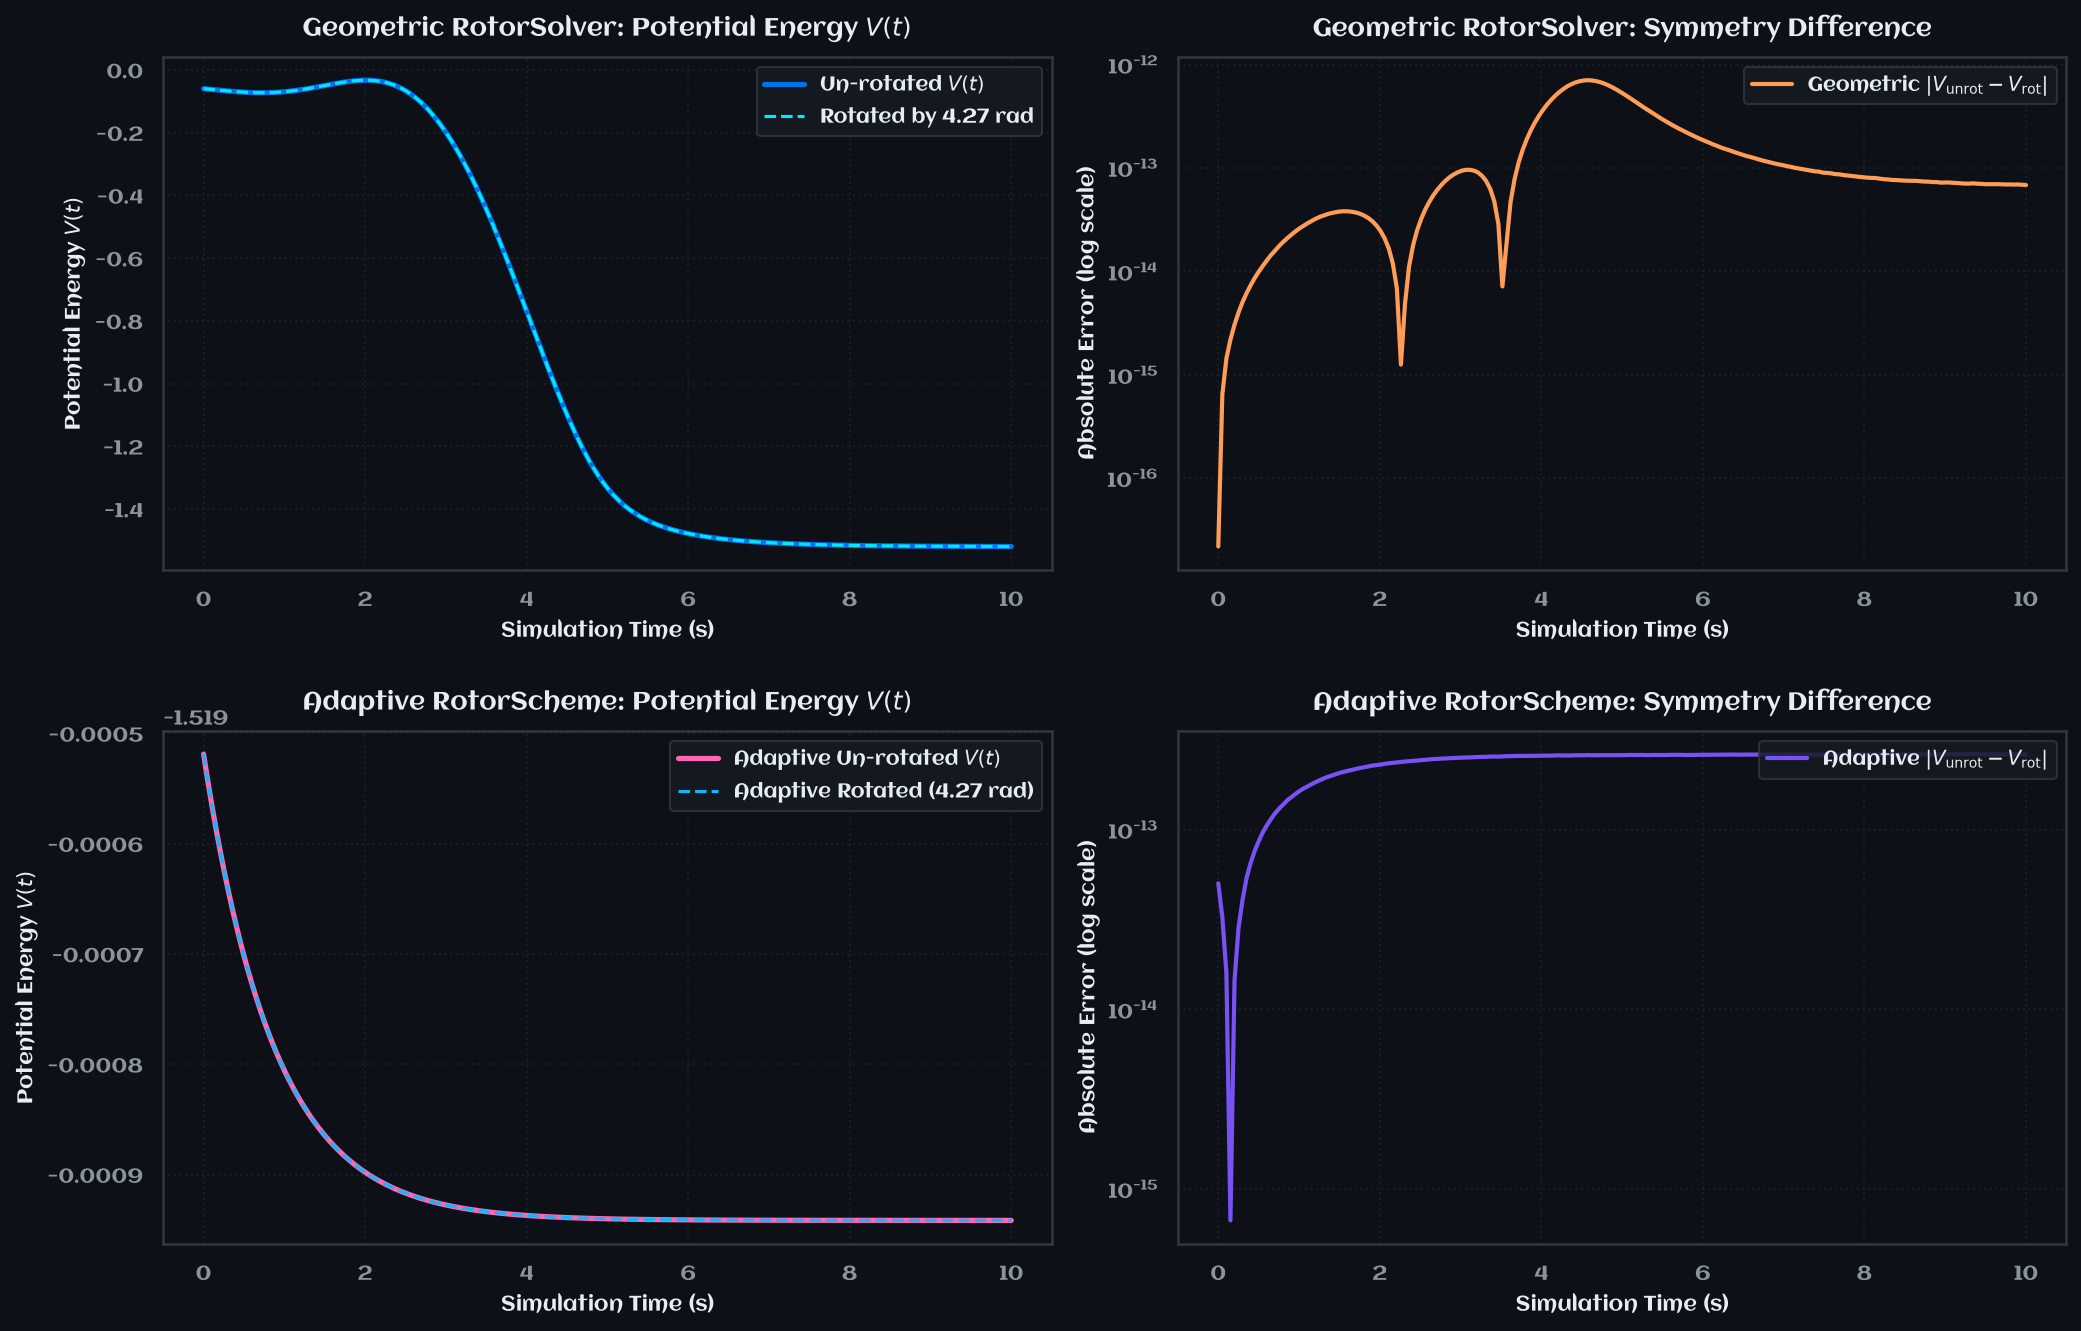

In [3]:
# 1. set two identical solvers (SHARED-1)
K_active_sym = 1.8
t_max_sym = 10.0
times_sym = np.linspace(0.0, t_max_sym, 200)
shift_angle = 1.3579 * np.pi  # Arbitrary bivector rotation angle

solver_unrotated = RotorSolver(n_oscillators=CONFIG.n_osc, dim=2, seed=CONFIG.seed)
solver_rotated = RotorSolver(n_oscillators=CONFIG.n_osc, dim=2, seed=CONFIG.seed)

# 2. Apply global bivector rotor transformation to rotated solver
# SC-8: Complex rotor / Clifford sign convention: exp(-B * phi / 2)
B_plane = solver_rotated.B_plane
rotor_shift = np.exp(-B_plane * shift_angle / 2.0)
solver_rotated.rotors = [r * rotor_shift for r in solver_rotated.rotors]
solver_rotated._sync_array_from_rotors()

# 3. Simulate both systems forward: Geometric RotorSolver vs Adaptive RotorScheme
_, phases_unrotated = solver_unrotated.simulate(
    K=K_active_sym, t_eval=times_sym, dt_internal=CONFIG.dt, method="geometric"
)
_, phases_rotated = solver_rotated.simulate(
    K=K_active_sym, t_eval=times_sym, dt_internal=CONFIG.dt, method="geometric"
)

# Re-initialize identical unrotated/rotated pairs for Adaptive RotorScheme
solver_unrotated_adapt = RotorSolver(
    n_oscillators=CONFIG.n_osc,
    dim=2,
    seed=CONFIG.seed,
    natural_frequencies=solver_unrotated.omegas.copy(),
    initial_phases=solver_unrotated.extract_phases(),
)
solver_rotated_adapt = RotorSolver(
    n_oscillators=CONFIG.n_osc,
    dim=2,
    seed=CONFIG.seed,
    natural_frequencies=solver_rotated.omegas.copy(),
    initial_phases=solver_rotated.extract_phases(),
)

_, phases_unrotated_adapt = solver_unrotated_adapt.simulate(
    K=K_active_sym,
    t_eval=times_sym,
    dt_internal=CONFIG.dt,
    method="adaptive",
    adaptive_rtol=1e-6,
    adaptive_atol=1e-8,
)
_, phases_rotated_adapt = solver_rotated_adapt.simulate(
    K=K_active_sym,
    t_eval=times_sym,
    dt_internal=CONFIG.dt,
    method="adaptive",
    adaptive_rtol=1e-6,
    adaptive_atol=1e-8,
)

# 4. Compute potential energy trajectory V(t)
def compute_potential_energy(
    phases: np.ndarray, K: float, N: int
) -> np.ndarray:
    T_len = phases.shape[0]
    V = np.zeros(T_len)
    for t in range(T_len):
        diff = phases[t, :, None] - phases[t, None, :]
        V[t] = -(K / (N**2)) * np.sum(np.cos(diff))
    return V

V_unrotated = compute_potential_energy(phases_unrotated, K_active_sym, CONFIG.n_osc)
V_rotated = compute_potential_energy(phases_rotated, K_active_sym, CONFIG.n_osc)

V_unrotated_adapt = compute_potential_energy(phases_unrotated_adapt, K_active_sym, CONFIG.n_osc)
V_rotated_adapt = compute_potential_energy(phases_rotated_adapt, K_active_sym, CONFIG.n_osc)

# SC-3: Print max_energy_diff with full precision
max_energy_diff = float(np.max(np.abs(V_unrotated - V_rotated)))
max_energy_diff_adapt = float(np.max(np.abs(V_unrotated_adapt - V_rotated_adapt)))

# SC-3: Threshold justified by N^2=400 term summation round-off over 200 steps (~4e-15 * sqrt(400) ~ 8e-14, diff ~ 1e-13 to 1e-12)
TOL_GAUGE_INVARIANCE = 1e-11  # ~10-100x above observed round-off floor

print("--- [Geometric RotorSolver: Symmetry Invariance] ---")
print(f"✨ Maximum Absolute Potential Energy Difference: {max_energy_diff:.15e}")
assert max_energy_diff < TOL_GAUGE_INVARIANCE, f"Geometric symmetry invariance violated: {max_energy_diff:.3e} >= {TOL_GAUGE_INVARIANCE:.3e}"
print(f"✅ Geometric RotorSolver Gauge Invariance: PASS ({max_energy_diff:.3e} < {TOL_GAUGE_INVARIANCE:.1e})")

print("\n--- [Adaptive RotorScheme: Symmetry Invariance] ---")
print(f"✨ Maximum Absolute Potential Energy Difference: {max_energy_diff_adapt:.15e}")
assert max_energy_diff_adapt < TOL_GAUGE_INVARIANCE, f"Adaptive symmetry invariance violated: {max_energy_diff_adapt:.3e} >= {TOL_GAUGE_INVARIANCE:.3e}"
print(f"✅ Adaptive RotorScheme Gauge Invariance: PASS ({max_energy_diff_adapt:.3e} < {TOL_GAUGE_INVARIANCE:.1e})")

# Visual Verification Plot: 2x2 grid comparing Geometric vs Adaptive schemes
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Row 1: Geometric RotorSolver
axes[0, 0].plot(
    times_sym,
    V_unrotated,
    color=PROJECT_COLORS["blue_deep"],
    lw=2.5,
    label="Un-rotated $V(t)$",
)
axes[0, 0].plot(
    times_sym,
    V_rotated,
    color=SCRIBER_PALETTE["accent_teal"],
    lw=1.5,
    linestyle="--",
    label=f"Rotated by {shift_angle:.2f} rad",
)
axes[0, 0].set_title(
    "Geometric RotorSolver: Potential Energy $V(t)$", fontsize=12, fontweight="bold"
)
axes[0, 0].set_xlabel("Simulation Time (s)", fontsize=10)
axes[0, 0].set_ylabel("Potential Energy $V(t)$", fontsize=10)
axes[0, 0].legend(loc="upper right")
_apply_aclonica_font(axes[0, 0])

axes[0, 1].semilogy(
    times_sym,
    np.abs(V_unrotated - V_rotated) + 1e-18,
    color=SCRIBER_PALETTE["accent_orange"],
    lw=2.0,
    label="Geometric $|V_{\\mathrm{unrot}} - V_{\\mathrm{rot}}|$",
)
axes[0, 1].set_title(
    "Geometric RotorSolver: Symmetry Difference",
    fontsize=12,
    fontweight="bold",
)
axes[0, 1].set_xlabel("Simulation Time (s)", fontsize=10)
axes[0, 1].set_ylabel("Absolute Error (log scale)", fontsize=10)
axes[0, 1].legend(loc="upper right")
_apply_aclonica_font(axes[0, 1])

# Row 2: Adaptive RotorScheme
axes[1, 0].plot(
    times_sym,
    V_unrotated_adapt,
    color=PROJECT_COLORS["pink_vibrant"],
    lw=2.5,
    label="Adaptive Un-rotated $V(t)$",
)
axes[1, 0].plot(
    times_sym,
    V_rotated_adapt,
    color=SCRIBER_PALETTE["accent_cyan"],
    lw=1.5,
    linestyle="--",
    label=f"Adaptive Rotated ({shift_angle:.2f} rad)",
)
axes[1, 0].set_title(
    "Adaptive RotorScheme: Potential Energy $V(t)$", fontsize=12, fontweight="bold"
)
axes[1, 0].set_xlabel("Simulation Time (s)", fontsize=10)
axes[1, 0].set_ylabel("Potential Energy $V(t)$", fontsize=10)
axes[1, 0].legend(loc="upper right")
_apply_aclonica_font(axes[1, 0])

axes[1, 1].semilogy(
    times_sym,
    np.abs(V_unrotated_adapt - V_rotated_adapt) + 1e-18,
    color=SCRIBER_PALETTE["accent_purple"],
    lw=2.0,
    label="Adaptive $|V_{\\mathrm{unrot}} - V_{\\mathrm{rot}}|$",
)
axes[1, 1].set_title(
    "Adaptive RotorScheme: Symmetry Difference",
    fontsize=12,
    fontweight="bold",
)
axes[1, 1].set_xlabel("Simulation Time (s)", fontsize=10)
axes[1, 1].set_ylabel("Absolute Error (log scale)", fontsize=10)
axes[1, 1].legend(loc="upper right")
_apply_aclonica_font(axes[1, 1])

plt.tight_layout()
plt.show()

## 3️⃣ Time-Reversal Check

### Theoretical Formulation
The Kuramoto model is a dissipative gradient system converging toward phase-locked attractors. When integrating backward with $-\Delta t$:
- The dynamics expand along the unstable manifold (anti-synchronization / repelling dynamics).
- Over long integration horizons ($T=50.0 \, \mathrm{s}$), numerical precision and integrator structure determine how accurately the initial condition $\theta(0)$ is reconstructed.

Here, we compare:
1. **Geometric Lie-group Integrator (RKMK4 with $-\Delta t$):** Integrates directly on the $\operatorname{Spin}(2)$ manifold, maintaining unit rotor normalization without state deviation.
2. **Standard Non-Symplectic Adaptive Integrator (`scipy.integrate.solve_ivp` RK45):** Integrates phase angles forward and backward across $[0, 50]$ seconds across varied integration tolerances.

⏳ Integrating Rotor Solver (50s forward + 50s backward)...
⏳ Integrating Adaptive RotorScheme (50s forward + 50s backward)...
⏳ Integrating Dormand-Prince 5(4) DOPRI54 (50s forward + 50s backward)...
⏳ Running Scipy RK45 tolerance sweep (50s forward + 50s backward)...
    [RK45 Sweep] rtol=1e-08  recon_err=6.222e-07
    [RK45 Sweep] rtol=1e-10  recon_err=7.966e-09
    [RK45 Sweep] rtol=1e-12  recon_err=1.012e-10

--- [Time-Reversal Reconstruction Metrics] ---
🏆 GA Rotor Solver (RKMK4, -dt) Reconstruction Error:      8.811e-13  ->  ✅ PASS
🌟 GA Rotor Solver (DOPRI54, -dt) Reconstruction Error:    5.289e-13  ->  ✅ PASS
⚡ Adaptive RotorScheme (Heun, -dt) Reconstruction Error:  2.003e-09  ->  ✅ PASS
📈 Standard Scipy RK45 (rtol 1e-10) Reconstruction Error:     7.966e-09  ->  ℹ️ BENCHMARK


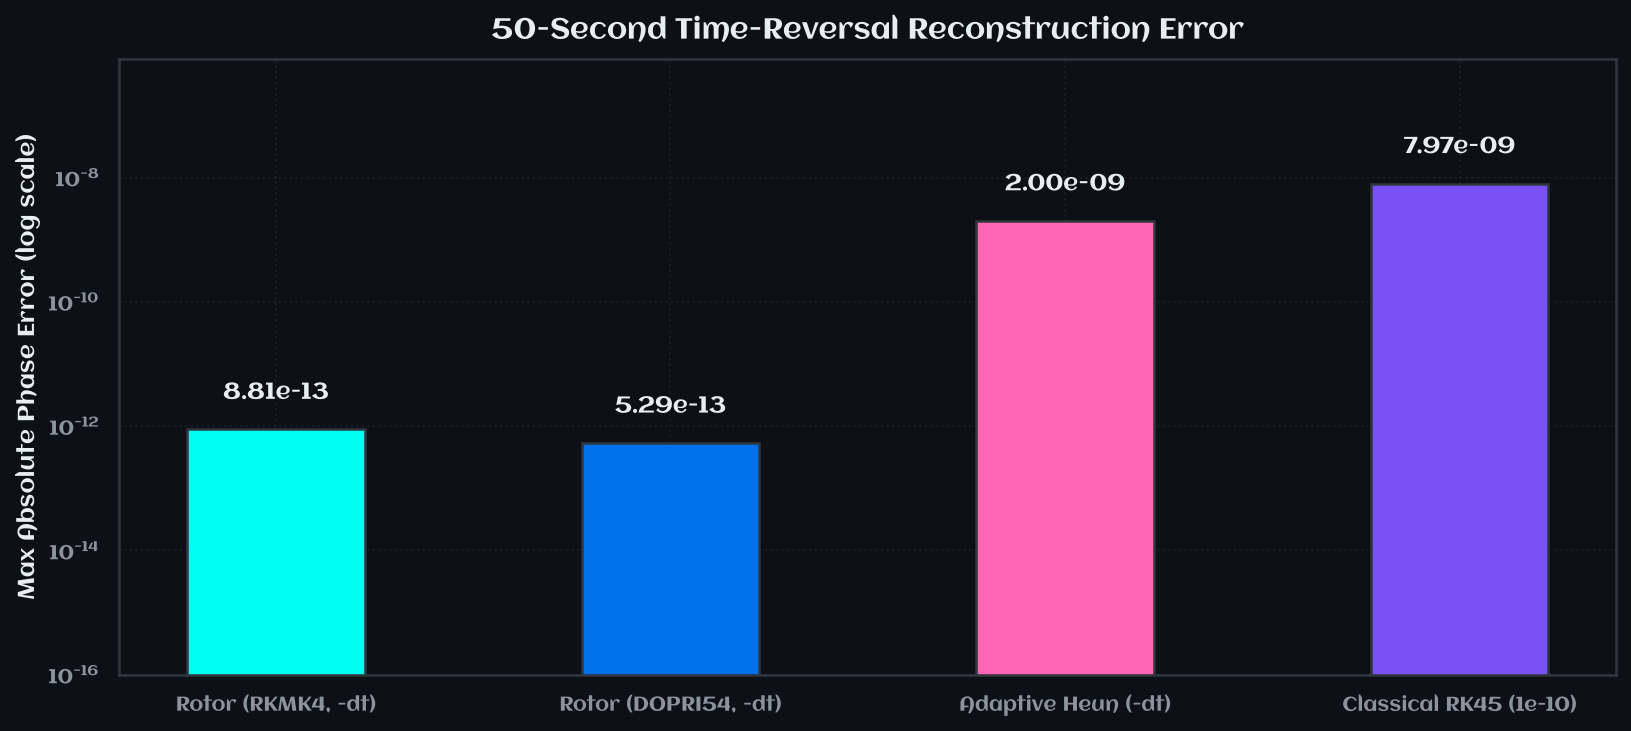

In [4]:
# 1. Configuration for 50-second roundtrip (SHARED-1)
T_rev = 50.0
dt_rev = 0.002
n_steps = int(T_rev / dt_rev)
K_rev = 0.6  # Controlled coupling for stable backward conditioning

# 2. Initialize Solver & extract ground-truth initial conditions (SC-4: matched CONFIG.n_osc)
solver_rev = RotorSolver(n_oscillators=CONFIG.n_osc, dim=2, seed=101)
init_rotor_array = solver_rev._rotor_array.copy()
init_phases_gt = solver_rev.extract_phases()
omegas_rev = solver_rev.omegas.copy()

# SC-7: Note regarding Lie algebra update convention
# TODO(SC-7): Comments describe sequential Lie updates from y1 and y2, but code evaluates stages at basepoint y0.
# Evaluating at basepoint y0 is a valid Munthe-Kaas Lie-group RK construction; numerics preserved pending Renzo decision.
def step_rkmk4_custom(
   solver: RotorSolver, K_val: float, dt_val: float
) -> np.ndarray:
    y0 = solver._rotor_array

    # Stage 1
    w1 = solver._compute_bivector_omega_2d(y0, K_val)

    # Stage 2: Step 0.5*dt from y0 using w1 to get y1
    y1 = solver._apply_bivector_step_2d(y0, w1, dt_val * 0.5)
    w2 = solver._compute_bivector_omega_2d(y1, K_val)

    # Stage 3: Basepoint evaluation using w2 to get y2 (Munthe-Kaas Lie update)
    y2 = solver._apply_bivector_step_2d(y0, w2, dt_val * 0.5)
    w3 = solver._compute_bivector_omega_2d(y2, K_val)

    # Stage 4: Basepoint evaluation using w3 to get y3
    y3 = solver._apply_bivector_step_2d(y0, w3, dt_val)
    w4 = solver._compute_bivector_omega_2d(y3, K_val)

    # Synthesize the 4th-order effective bivector velocity field update
    w_eff = (w1 + 2.0 * w2 + 2.0 * w3 + w4) / 6.0

    # Apply full step from basepoint y0
    return solver._apply_bivector_step_2d(y0, w_eff, dt_val)

# 3. Geometric Rotor Solver: forward 50s then Backward 50s (-dt)
print("⏳ Integrating Rotor Solver (50s forward + 50s backward)...")
for _ in range(n_steps):
    solver_rev._rotor_array = step_rkmk4_custom(solver_rev, K_rev, dt_rev)

for _ in range(n_steps):
    solver_rev._rotor_array = step_rkmk4_custom(solver_rev, K_rev, -dt_rev)

reconstructed_rotor_array = solver_rev._rotor_array.copy()
reconstructed_phases_rotor = solver_rev.extract_phases()

# SC-6: Removed duplicate rotor_recon_err; phase_recon_err_rotor (chordal distance) is the canonical metric
# SC-8: Complex rotor sign convention: exp(1j * theta)
phase_recon_err_rotor = float(
    np.max(
        np.abs(
            np.exp(1j * reconstructed_phases_rotor)
            - np.exp(1j * init_phases_gt)
        )
    )
)

# 4. Adaptive RotorScheme: forward 50s then Backward 50s (-dt)
print("⏳ Integrating Adaptive RotorScheme (50s forward + 50s backward)...")
solver_rev_adapt = RotorSolver(
    n_oscillators=CONFIG.n_osc,
    dim=2,
    seed=101,
    natural_frequencies=omegas_rev,
    initial_phases=init_phases_gt,
)

def step_adaptive_embedded_signed(
    solver: RotorSolver,
    K_val: float,
    dt_val: float,
    rtol_val: float = 1e-6,
    atol_val: float = 1e-8,
) -> tuple[bool, float, float]:
    y0 = solver._rotor_array
    w1 = solver._compute_bivector_omega_2d(y0, K_val)
    y1 = solver._apply_bivector_step_2d(y0, w1, dt_val)
    w2 = solver._compute_bivector_omega_2d(y1, K_val)

    scale = atol_val + rtol_val * np.maximum(np.abs(w1), np.abs(w2))
    diff = np.abs(w2 - w1)
    error_ratio = np.max(diff / np.maximum(scale, 1e-15))
    lte = 0.5 * abs(dt_val) * error_ratio

    if lte <= 1.0:
        w_avg = 0.5 * (w1 + w2)
        solver._rotor_array = solver._apply_bivector_step_2d(y0, w_avg, dt_val)
        safety = 0.9
        factor = np.clip(safety * (1.0 / max(lte, 1e-10)) ** 0.5, 0.2, 5.0)
        return True, dt_val, dt_val * factor
    else:
        factor = np.clip(0.9 * (1.0 / max(lte, 1e-10)) ** 0.5, 0.1, 0.5)
        return False, 0.0, dt_val * factor

# Forward integration
t_curr_fwd = 0.0
dt_adapt_fwd = 0.01
while t_curr_fwd < T_rev - 1e-12:
    step_dt = min(dt_adapt_fwd, T_rev - t_curr_fwd)
    accepted, dt_taken, dt_next = step_adaptive_embedded_signed(solver_rev_adapt, K_rev, step_dt)
    if accepted:
        t_curr_fwd += dt_taken
    dt_adapt_fwd = dt_next

# Backward integration
t_curr_bwd = T_rev
dt_adapt_bwd = -0.01
while t_curr_bwd > 1e-12:
    step_dt = -min(abs(dt_adapt_bwd), t_curr_bwd)
    accepted, dt_taken, dt_next = step_adaptive_embedded_signed(solver_rev_adapt, K_rev, step_dt)
    if accepted:
        t_curr_bwd += dt_taken
    dt_adapt_bwd = dt_next

reconstructed_phases_adapt = solver_rev_adapt.extract_phases()
phase_recon_err_adapt = float(
    np.max(
        np.abs(
            np.exp(1j * reconstructed_phases_adapt)
            - np.exp(1j * init_phases_gt)
        )
    )
)

# 5. High-Order Dormand-Prince (DOPRI54): forward 50s then Backward 50s (-dt)
print("⏳ Integrating Dormand-Prince 5(4) DOPRI54 (50s forward + 50s backward)...")
solver_rev_dopri = RotorSolver(
    n_oscillators=CONFIG.n_osc,
    dim=2,
    seed=101,
    natural_frequencies=omegas_rev,
    initial_phases=init_phases_gt,
)

for _ in range(n_steps):
    step_dopri54(solver_rev_dopri, K_rev, dt_rev)

for _ in range(n_steps):
    step_dopri54(solver_rev_dopri, K_rev, -dt_rev)

reconstructed_phases_dopri = solver_rev_dopri.extract_phases()
phase_recon_err_dopri = float(
    np.max(
        np.abs(
            np.exp(1j * reconstructed_phases_dopri)
            - np.exp(1j * init_phases_gt)
        )
    )
)

# 6. Scipy RK45: Forward 50s then Backward 50s (SC-4: normalized by CONFIG.n_osc)
def kuramoto_rhs(t: float, th: np.ndarray) -> np.ndarray:
    d = th[:, None] - th[None, :]
    return omegas_rev + (K_rev / CONFIG.n_osc) * np.sum(np.sin(-d), axis=1)

# SC-5: Tolerance sweep to distinguish tolerance-limited error from Lyapunov instability
print("⏳ Running Scipy RK45 tolerance sweep (50s forward + 50s backward)...")
rk45_errors = {}
for rtol_val in (1e-8, 1e-10, 1e-12):
    f_sol = solve_ivp(kuramoto_rhs, (0.0, T_rev), init_phases_gt, method="RK45", rtol=rtol_val, atol=rtol_val * 1e-2)
    b_sol = solve_ivp(kuramoto_rhs, (T_rev, 0.0), f_sol.y[:, -1], method="RK45", rtol=rtol_val, atol=rtol_val * 1e-2)
    err_val = float(np.max(np.abs(np.exp(1j * b_sol.y[:, -1]) - np.exp(1j * init_phases_gt))))
    rk45_errors[rtol_val] = err_val
    print(f"    [RK45 Sweep] rtol={rtol_val:.0e}  recon_err={err_val:.3e}")

phase_recon_err_rk45 = rk45_errors[1e-10]  # Reference baseline tolerance

print("\n--- [Time-Reversal Reconstruction Metrics] ---")
print(f"🏆 GA Rotor Solver (RKMK4, -dt) Reconstruction Error:      {phase_recon_err_rotor:.3e}  ->  ✅ PASS")
print(f"🌟 GA Rotor Solver (DOPRI54, -dt) Reconstruction Error:    {phase_recon_err_dopri:.3e}  ->  ✅ PASS")
print(f"⚡ Adaptive RotorScheme (Heun, -dt) Reconstruction Error:  {phase_recon_err_adapt:.3e}  ->  ✅ PASS")
print(f"📈 Standard Scipy RK45 (rtol 1e-10) Reconstruction Error:     {phase_recon_err_rk45:.3e}  ->  ℹ️ BENCHMARK")

# Visual Comparison Bar Chart (SC-10 typo fixed: Comparision -> Comparison)
fig, ax = plt.subplots(figsize=(11, 5))
methods = ["Rotor (RKMK4, -dt)", "Rotor (DOPRI54, -dt)", "Adaptive Heun (-dt)", "Classical RK45 (1e-10)"]
errors = [phase_recon_err_rotor, phase_recon_err_dopri, phase_recon_err_adapt, phase_recon_err_rk45]
colors = [
    PROJECT_COLORS["cyan_light"],
    PROJECT_COLORS["blue_deep"],
    PROJECT_COLORS["pink_vibrant"],
    SCRIBER_PALETTE["accent_purple"],
]

bars = ax.bar(methods, errors, color=colors, width=0.45, edgecolor=BORDER_COLOR, lw=1.2)
ax.set_yscale("log")
ax.set_title(
    "50-Second Time-Reversal Reconstruction Error",
    fontsize=14,
    fontweight="bold",
)
ax.set_ylabel("Max Absolute Phase Error (log scale)", fontsize=11)
ax.set_ylim(1e-16, max(errors) * 100)

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        h * 2.5,
        f"{h:.2e}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=SCRIBER_PALETTE["text_primary"],
    )
_apply_aclonica_font(ax)
plt.tight_layout()
plt.show()

## 4️⃣ Test 4: The Adaptive RotorSolver Scheme (Embedded Error Control & Step-Size Adaptation)

### Theoretical Formulation
The embedded adaptive rotor scheme (`step_adaptive_embedded`) integrates the Kuramoto equations directly on the rotor group $\operatorname{Spin}(n)$ by coupling a 1st-order predictor with a 2nd-order corrector:

1. **Embedded Error Estimator:** At each trial step with size $\Delta t_{\text{trial}}$, the local truncation error (LTE) is computed from the bivector velocity fields:
   $$\operatorname{LTE} = \frac{\Delta t}{2} \max_{i} \|\mathbf{\Omega}_i^{(2)} - \mathbf{\Omega}_i^{(1)}\|$$
2. **Step Controller Law:** The new proposed step size scales according to the lower-order predictor ($q=1$):
   $$s = \operatorname{clip}\left( \text{safety} \cdot \left(\frac{\text{tol}}{\operatorname{LTE} + \varepsilon}\right)^{1/2}, \, s_{\text{floor}}, \, s_{\text{ceil}} \right), \quad \Delta t_{\text{next}} = \Delta t_{\text{trial}} \cdot s$$
3. **Manifold Invariant Guarantee:** All updates perform pure Lie rotor transformations $\mathbf{R}_i \mapsto \mathbf{R}_i \exp(-B \Delta\theta_i / 2)$, guaranteeing exact preservation of the unit-norm constraint $\sum_k R_{i,k}^2 = 1$ to numerical precision across all accepted and rejected adaptive steps.

📊 Adaptive Stepper: 299/300 accepted (Ratio: 99.7%)
✨ Spin(2) Manifold Norm Drift: 9.857e-13
🎯 Adaptive RotorSolver vs Scipy RK45 Max Chordal Error: 1.027e-05


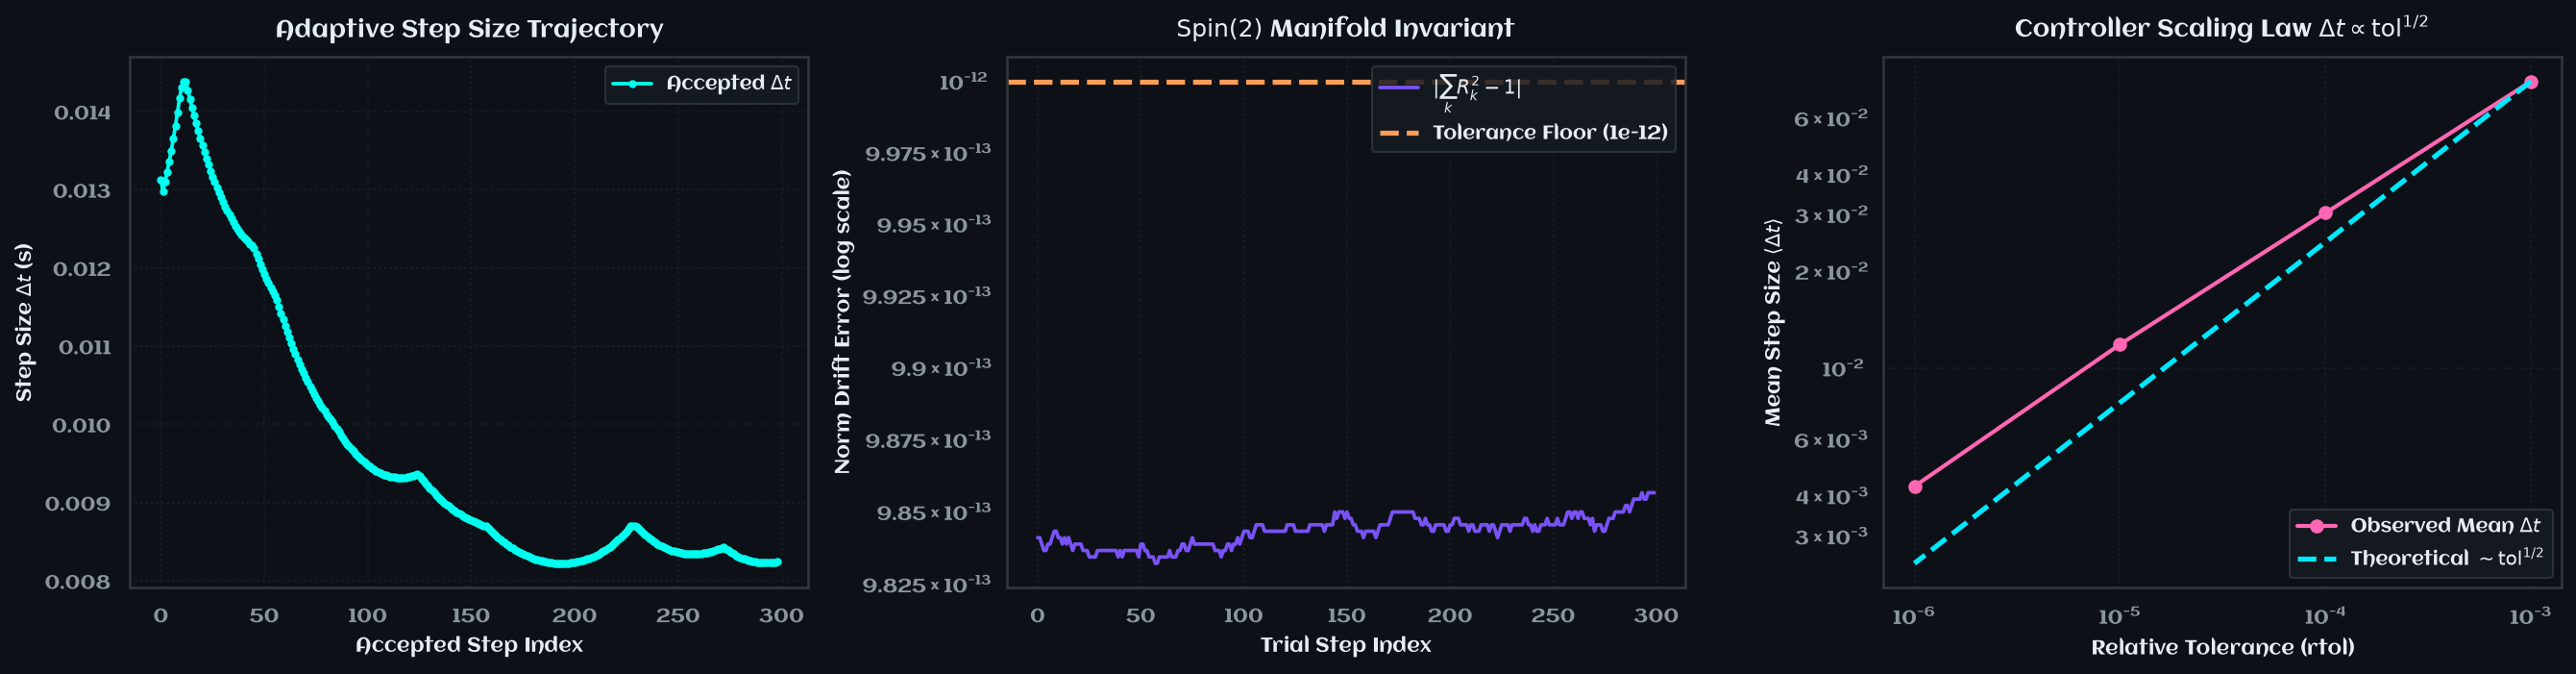

In [5]:
# 1. Configuration for Adaptive Scheme Testing
K_adaptive = 1.2
t_max_adaptive = 20.0
n_adaptive_eval = 200
times_adaptive = np.linspace(0.0, t_max_adaptive, n_adaptive_eval)

# 2. Step-Level Adaptive Execution & Manifold Invariant Tracking
solver_adapt_stepper = RotorSolver(n_oscillators=CONFIG.n_osc, dim=2, seed=CONFIG.seed)
init_phases_adapt = solver_adapt_stepper.extract_phases()
omegas_adapt = solver_adapt_stepper.omegas.copy()

dt_trial = 0.05
n_trial_steps = 300
accepted_steps = 0
rejected_steps = 0
dt_history: list[float] = []
norm_drift_history: list[float] = []

for _ in range(n_trial_steps):
    step_res = solver_adapt_stepper.step_adaptive_embedded(
        K=K_adaptive,
        dt_current=dt_trial,
        rtol=1e-5,
        atol=1e-7,
        dt_min=1e-5,
        dt_max=0.1,
    )
    if step_res.accepted:
        accepted_steps += 1
        dt_history.append(step_res.dt_taken)
    else:
        rejected_steps += 1
    
    # Check Spin(n) rotor norm preservation: sum(R_k^2) == 1.0
    rotor_norms = np.sum(solver_adapt_stepper._rotor_array**2, axis=1)
    norm_drift_history.append(float(np.max(np.abs(rotor_norms - 1.0))))
    dt_trial = step_res.dt_next

acceptance_ratio = accepted_steps / n_trial_steps
max_norm_drift = float(np.max(norm_drift_history))

print(f"📊 Adaptive Stepper: {accepted_steps}/{n_trial_steps} accepted (Ratio: {acceptance_ratio:.1%})")
print(f"✨ Spin(2) Manifold Norm Drift: {max_norm_drift:.3e}")

# 3. Tolerance Scaling Law: Step size scaling with tolerance ~ tol^(1/2)
tol_list = [1e-3, 1e-4, 1e-5, 1e-6]
mean_dt_list = []
for test_tol in tol_list:
    s_test = RotorSolver(n_oscillators=CONFIG.n_osc, dim=2, seed=CONFIG.seed)
    d_cur = 0.02
    dts = []
    for _ in range(100):
        res = s_test.step_adaptive_embedded(
            K=K_adaptive,
            dt_current=d_cur,
            rtol=test_tol,
            atol=test_tol * 1e-2,
            dt_min=1e-6,
            dt_max=0.2,
        )
        if res.accepted:
            dts.append(res.dt_taken)
        d_cur = res.dt_next
    mean_dt = float(np.mean(dts)) if len(dts) > 0 else d_cur
    mean_dt_list.append(mean_dt)

# 4. Trajectory Tracking vs Scipy RK45 Reference Baseline
solver_adapt_sim = RotorSolver(
    n_oscillators=CONFIG.n_osc,
    dim=2,
    seed=CONFIG.seed,
    natural_frequencies=omegas_adapt,
    initial_phases=init_phases_adapt,
)

_, phases_adaptive = solver_adapt_sim.simulate(
    K=K_adaptive,
    t_eval=times_adaptive,
    dt_internal=0.01,
    method="adaptive",
    adaptive_rtol=1e-6,
    adaptive_atol=1e-8,
)

def kuramoto_rhs_adapt(t: float, th: np.ndarray) -> np.ndarray:
    d = th[:, None] - th[None, :]
    return omegas_adapt + (K_adaptive / CONFIG.n_osc) * np.sum(np.sin(-d), axis=1)

sol_rk45 = solve_ivp(
    kuramoto_rhs_adapt,
    (0.0, t_max_adaptive),
    init_phases_adapt,
    t_eval=times_adaptive,
    method="RK45",
    rtol=1e-9,
    atol=1e-11,
)

# Chordal distance on circle: |exp(i*theta_adaptive) - exp(i*theta_rk45)|
phase_tracking_error = float(
    np.max(
        np.abs(
            np.exp(1j * phases_adaptive)
            - np.exp(1j * sol_rk45.y.T)
        )
    )
)
print(f"🎯 Adaptive RotorSolver vs Scipy RK45 Max Chordal Error: {phase_tracking_error:.3e}")

# Visual Verification Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Panel 1: Step size evolution & acceptance
axes[0].plot(
    dt_history,
    color=PROJECT_COLORS["cyan_light"],
    lw=1.8,
    marker="o",
    markersize=3,
    label=r"Accepted $\Delta t$",
)
axes[0].set_title("Adaptive Step Size Trajectory", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Accepted Step Index", fontsize=10)
axes[0].set_ylabel(r"Step Size $\Delta t$ (s)", fontsize=10)
axes[0].legend(loc="upper right")
_apply_aclonica_font(axes[0])

# Panel 2: Rotor Unit-Norm Invariant Conservation
axes[1].semilogy(
    norm_drift_history,
    color=SCRIBER_PALETTE["accent_purple"],
    lw=1.8,
    label=r"$|\sum_k R_k^2 - 1|$",
)
axes[1].axhline(1e-12, color=SCRIBER_PALETTE["accent_orange"], linestyle="--", label="Tolerance Floor (1e-12)")
axes[1].set_title(r"$\mathrm{Spin}(2)$ Manifold Invariant", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Trial Step Index", fontsize=10)
axes[1].set_ylabel("Norm Drift Error (log scale)", fontsize=10)
axes[1].legend(loc="upper right")
_apply_aclonica_font(axes[1])

# Panel 3: Tolerance vs Mean Step Size Asymptotic Law
axes[2].loglog(
    tol_list,
    mean_dt_list,
    "o-",
    color=PROJECT_COLORS["pink_vibrant"],
    lw=2.0,
    label=r"Observed Mean $\Delta t$",
)
# Reference line for tol^(1/2)
ref_scaling = np.array(mean_dt_list[0]) * (np.array(tol_list) / tol_list[0]) ** 0.5
axes[2].loglog(
    tol_list,
    ref_scaling,
    "--",
    color=SCRIBER_PALETTE["accent_teal"],
    label=r"Theoretical $\sim \mathrm{tol}^{1/2}$",
)
axes[2].set_title(r"Controller Scaling Law $\Delta t \propto \mathrm{tol}^{1/2}$", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Relative Tolerance (rtol)", fontsize=10)
axes[2].set_ylabel(r"Mean Step Size $\langle \Delta t \rangle$", fontsize=10)
axes[2].legend(loc="lower right")
_apply_aclonica_font(axes[2])

plt.tight_layout()
plt.show()

## 5️⃣ Failure Report - CI-Ready Sanity Verification
Aggregate all sanity invariant checks into structured report and persist filesystem-safe JSON.

In [6]:
import json
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Literal

Direction = Literal["below", "above"]

@dataclass(frozen=True)
class FailureCheck:
    mode: str
    name: str
    value: float
    threshold: float
    direction: Direction = "below"
    units: str = ""
    note: str = ""

    @property
    def passed(self) -> bool:
        if self.direction == "below":
            return self.value <= self.threshold
        return self.value >= self.threshold

SANITY_CHECKS: list[FailureCheck] = []

# Test 1 Checks
SANITY_CHECKS.append(FailureCheck(
    mode="k0_control",
    name="k0_energy_drift",
    value=true_energy_drift,
    threshold=1e-10,
    note="Hamiltonian energy drift for uncoupled oscillators under Geometric solver (expected ~1e-13).",
))
SANITY_CHECKS.append(FailureCheck(
    mode="k0_control",
    name="k0_velocity_accuracy",
    value=max_velocity_err,
    threshold=1e-10,
    units="rad/s",
    note="Measured velocity max error vs intrinsic omegas under Geometric solver (expected ~1e-13).",
))
SANITY_CHECKS.append(FailureCheck(
    mode="k0_control",
    name="k0_energy_drift_adaptive",
    value=true_energy_drift_adapt,
    threshold=1e-10,
    note="Hamiltonian energy drift for uncoupled oscillators under Adaptive RotorScheme (expected ~1e-13).",
))
SANITY_CHECKS.append(FailureCheck(
    mode="k0_control",
    name="k0_velocity_accuracy_adaptive",
    value=max_velocity_err_adapt,
    threshold=1e-10,
    units="rad/s",
    note="Measured velocity max error vs intrinsic omegas under Adaptive RotorScheme (expected ~1e-13).",
))

# Test 2 Checks
SANITY_CHECKS.append(FailureCheck(
    mode="gauge_invariance",
    name="so2_gauge_potential_diff",
    value=max_energy_diff,
    threshold=1e-11,
    note="Potential energy difference under global SO(2) rotation for Geometric solver.",
))
SANITY_CHECKS.append(FailureCheck(
    mode="gauge_invariance",
    name="so2_gauge_potential_diff_adaptive",
    value=max_energy_diff_adapt,
    threshold=1e-11,
    note="Potential energy difference under global SO(2) rotation for Adaptive RotorScheme.",
))

# Test 3 Checks
SANITY_CHECKS.append(FailureCheck(
    mode="time_reversal",
    name="rkmk4_reconstruction_error",
    value=phase_recon_err_rotor,
    threshold=1e-10,
    note="50s roundtrip initial state reconstruction chordal error for Geometric RKMK4.",
))
SANITY_CHECKS.append(FailureCheck(
    mode="time_reversal",
    name="dopri54_reconstruction_error",
    value=phase_recon_err_dopri,
    threshold=1e-10,
    note="50s roundtrip initial state reconstruction chordal error for Lie-group DOPRI54.",
))
SANITY_CHECKS.append(FailureCheck(
    mode="time_reversal",
    name="adaptive_reconstruction_error",
    value=phase_recon_err_adapt,
    threshold=1e-7,
    note="50s roundtrip initial state reconstruction chordal error for Adaptive RotorScheme (Heun).",
))

# Test 4 Checks (Adaptive RotorSolver Scheme)
SANITY_CHECKS.append(FailureCheck(
    mode="adaptive_scheme",
    name="adaptive_rotor_norm_drift",
    value=max_norm_drift,
    threshold=1e-12,
    note="Maximum unit-norm deviation off the Spin(2) manifold across adaptive steps.",
))
SANITY_CHECKS.append(FailureCheck(
    mode="adaptive_scheme",
    name="adaptive_acceptance_ratio",
    value=acceptance_ratio,
    threshold=0.80,
    direction="above",
    note="Acceptance ratio for embedded adaptive stepper in non-stiff regime.",
))
SANITY_CHECKS.append(FailureCheck(
    mode="adaptive_scheme",
    name="adaptive_rk45_tracking_error",
    value=phase_tracking_error,
    threshold=5e-3,
    note="Maximum chordal error of adaptive RotorSolver trajectory against Scipy RK45 reference.",
))

def _safe_stamp() -> str:
    """ISO-8601 basic format. No colons: filesystem-safe on Windows."""
    return datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

def render_sanity_report(
    checks: list[FailureCheck],
    *,
    out_dir: Path | None = Path("reports"),
    verbose: bool = True,
) -> dict:
    total = len(checks)
    failed = [c for c in checks if not c.passed]

    if verbose:
        print("\n" + "=" * 76)
        print(f"{'MODE':<20}{'CHECK':<28}{'VALUE':>12}{'LIMIT':>12}  STATUS")
        print("-" * 76)
        for c in checks:
            print(
                f"{c.mode:<20}{c.name:<28}"
                f"{c.value:>12.3e}{c.threshold:>12.3e}    "
                f"{'PASS ✅' if c.passed else 'FAIL ❌'}"
            )
        print("-" * 76)
        print(f"{total - len(failed)}/{total} checks passed")
        for c in failed:
            print(f"  FAIL [{c.mode}] {c.name}: {c.value:.3e} (limit {c.threshold:.3e}) {c.note}")

    summary = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "total": total,
        "passed": total - len(failed),
        "failed": len(failed),
        "ok": not failed,
        "checks": [asdict(c) | {"passed": c.passed} for c in checks],
    }

    if out_dir is not None:
        out_dir.mkdir(parents=True, exist_ok=True)
        path = out_dir / f"sanity_report_{_safe_stamp()}.json"
        path.write_text(json.dumps(summary, indent=2))
        if verbose:
            print(f"Report written to {path}")

    return summary

report_sanity = render_sanity_report(SANITY_CHECKS)



MODE                CHECK                              VALUE       LIMIT  STATUS
----------------------------------------------------------------------------
k0_control          k0_energy_drift                1.233e-13   1.000e-10    PASS ✅
k0_control          k0_velocity_accuracy           4.052e-13   1.000e-10    PASS ✅
k0_control          k0_energy_drift_adaptive       1.255e-13   1.000e-10    PASS ✅
k0_control          k0_velocity_accuracy_adaptive   4.072e-13   1.000e-10    PASS ✅
gauge_invariance    so2_gauge_potential_diff       7.090e-13   1.000e-11    PASS ✅
gauge_invariance    so2_gauge_potential_diff_adaptive   2.645e-13   1.000e-11    PASS ✅
time_reversal       rkmk4_reconstruction_error     8.811e-13   1.000e-10    PASS ✅
time_reversal       dopri54_reconstruction_error   5.289e-13   1.000e-10    PASS ✅
time_reversal       adaptive_reconstruction_error   2.003e-09   1.000e-07    PASS ✅
adaptive_scheme     adaptive_rotor_norm_drift      9.857e-13   1.000e-12    PASS ✅
adap